# Análise de Resultados do Modelo

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

DATA_DIR = Path("../data")
df_val = pd.read_csv(DATA_DIR / "val_predictions.csv")
df_history = pd.read_csv(DATA_DIR / "training_history.csv")

df_val.head()

,y_true,y_prob,y_pred
0,1.0,0.992439,1.0
1,1.0,0.599192,1.0
2,0.0,0.129690,0.0
3,0.0,0.005796,0.0
4,1.0,0.141193,0.0


## 1. Métricas de Classificação (Conjunto de Validação)

In [2]:
y_true = df_val["y_true"]
y_pred = df_val["y_pred"]

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Acurácia:  {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("Relatório detalhado por classe:")
print(classification_report(y_true, y_pred, target_names=["Cat (0)", "Dog (1)"], digits=4))

Acurácia:  0.9154
Precisão:  0.9541
Recall:    0.8728
F1-Score:  0.9116

Relatório detalhado por classe:
              precision    recall  f1-score   support

     Cat (0)     0.8828    0.9580    0.9189      2500
     Dog (1)     0.9541    0.8728    0.9116      2500

    accuracy                         0.9154      5000
   macro avg     0.9184    0.9154    0.9152      5000
weighted avg     0.9184    0.9154    0.9152      5000



## 2. Matriz de Confusão

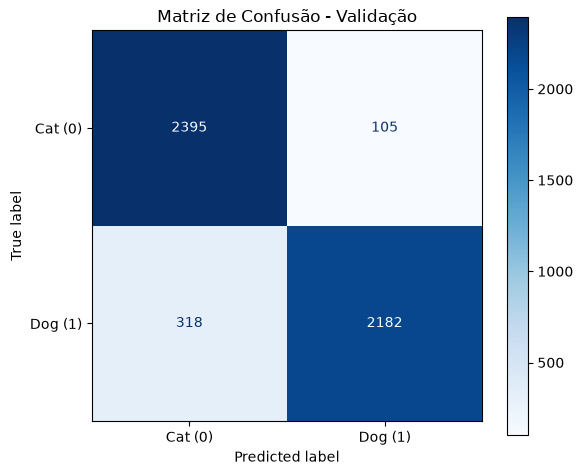

In [3]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cat (0)", "Dog (1)"])
disp.plot(cmap="Blues", values_format="d", ax=ax)
ax.set_title("Matriz de Confusão - Validação")
plt.tight_layout()
plt.show()

## 3. Histórico de Treinamento por Época

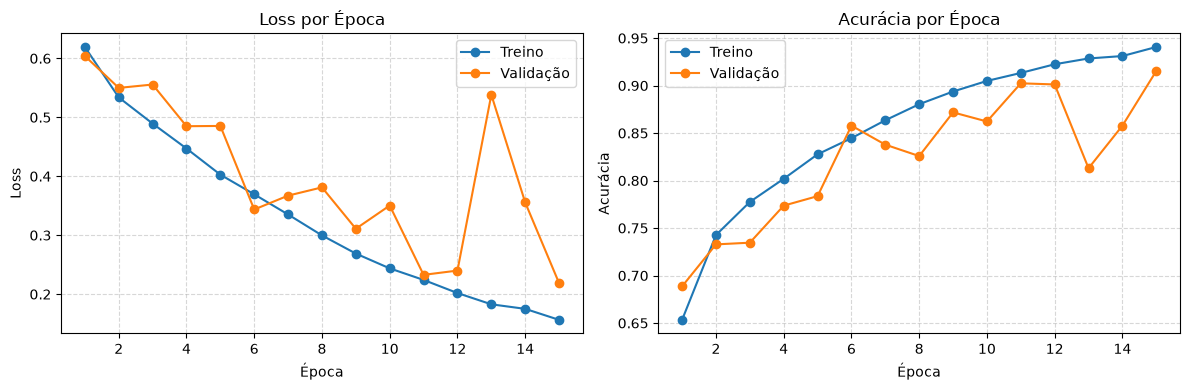

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(df_history["epoch"], df_history["train_loss"], marker="o", label="Treino")
axes[0].plot(df_history["epoch"], df_history["val_loss"], marker="o", label="Validação")
axes[0].set_title("Loss por Época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Acurácia
axes[1].plot(df_history["epoch"], df_history["train_acc"], marker="o", label="Treino")
axes[1].plot(df_history["epoch"], df_history["val_acc"], marker="o", label="Validação")
axes[1].set_title("Acurácia por Época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Exemplos

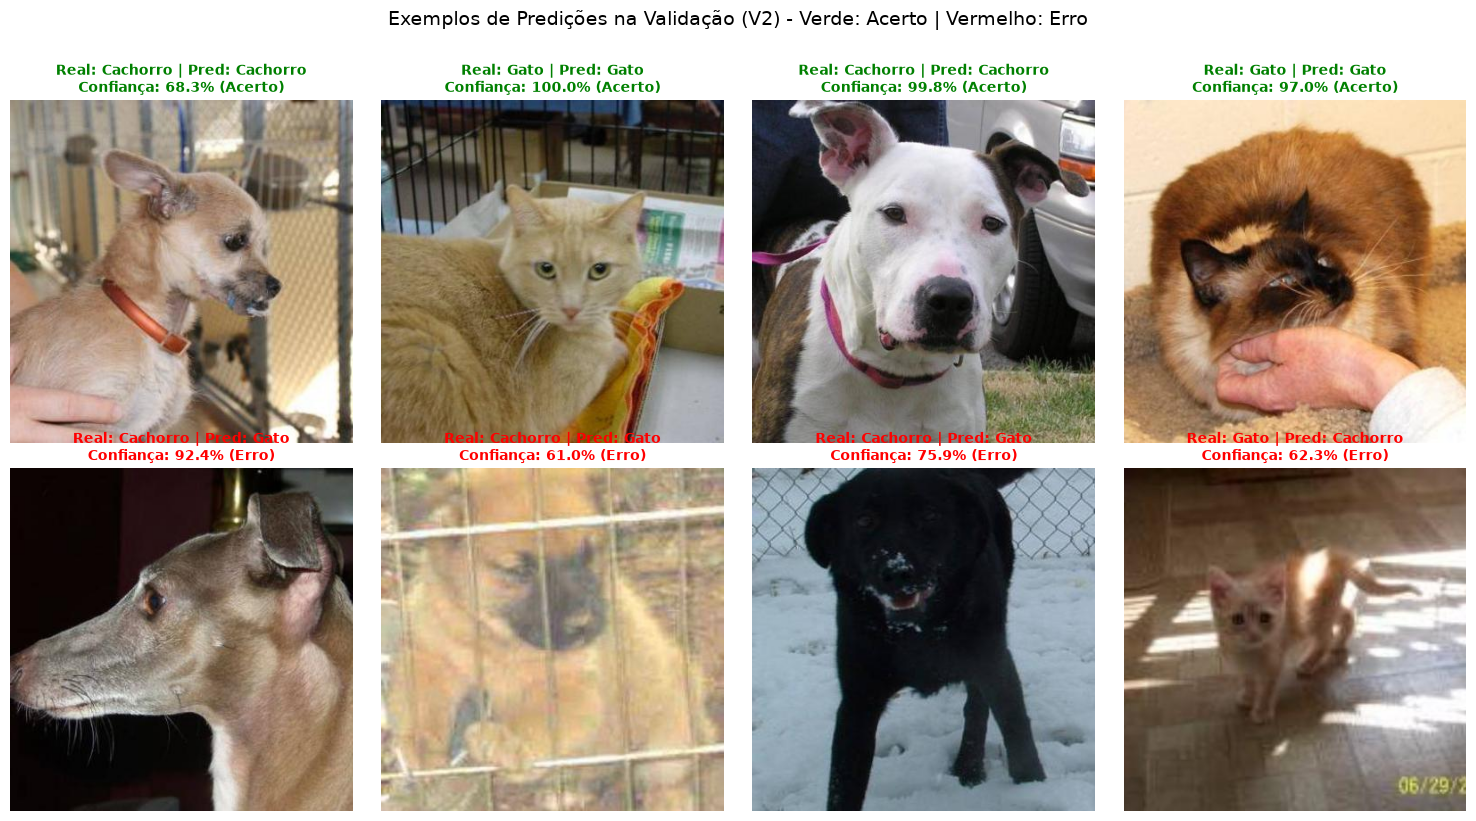

In [5]:
import sys
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Carregar a lista de arquivos da validação na mesma ordem do split
sys.path.append(str(Path("..").resolve()))
from src.dataset import get_train_files

_, val_files, _, _ = get_train_files()
df_val["file_path"] = val_files

# Selecionar 4 acertos e 4 erros para análise qualitativa
correct_samples = df_val[df_val["y_true"] == df_val["y_pred"]].sample(4, random_state=42)
error_samples = df_val[df_val["y_true"] != df_val["y_pred"]].sample(4, random_state=42)
sample_df = pd.concat([correct_samples, error_samples])

class_names = {0: "Gato", 1: "Cachorro"}

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = Image.open(row["file_path"])
    ax.imshow(img)
    ax.axis("off")

    real_label = class_names[int(row["y_true"])]
    pred_label = class_names[int(row["y_pred"])]
    prob = row["y_prob"]
    confidence = prob if row["y_pred"] == 1 else (1.0 - prob)

    is_correct = row["y_true"] == row["y_pred"]
    color = "green" if is_correct else "red"
    status = "Acerto" if is_correct else "Erro"

    ax.set_title(
        f"Real: {real_label} | Pred: {pred_label}\nConfiança: {confidence * 100:.1f}% ({status})",
        fontsize=10,
        color=color,
        fontweight="bold"
    )

plt.suptitle("Exemplos de Predições na Validação (V2) - Verde: Acerto | Vermelho: Erro", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 4. Avaliação em Pets IMPATech (Cachorros vs. Gatos)

In [6]:
import sys
from pathlib import Path
import json
import pandas as pd
from PIL import Image
import torch
from torchvision.transforms import CenterCrop, Compose, Normalize, Resize, ToTensor
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# ==========================================
# 1. CAMINHO DO DATASET PETS IMPATECH
# ==========================================
PETS_FOLDER = Path("../data/pets-impatech")

# ==========================================
# 2. CONFIGURAÇÕES DA V1
# ==========================================
IMAGE_SIZE = 224
MODEL_PATH = Path("../data/best_model.pth")
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# Carregar modelo
sys.path.append(str(Path("..").resolve()))
from src.model import CNN

device = torch.device("cpu" if torch.cuda.is_available() else "cuda")
if not MODEL_PATH.exists():
    print(f"Aviso: O modelo '{MODEL_PATH.name}' ainda não foi encontrado em data/. Treine o modelo antes de testar.")
elif not PETS_FOLDER.exists():
    print(f"Aviso: A pasta '{PETS_FOLDER}' não foi encontrada.")
else:
    model = CNN().to(device)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    model.eval()

    transform = Compose([
        Resize(IMAGE_SIZE),
        CenterCrop(IMAGE_SIZE),
        ToTensor(),
        Normalize(mean=NORM_MEAN, std=NORM_STD),
    ])

    # Mapeamento das pastas e rótulos (Gatos = 0, Cachorros = 1)
    class_subfolders = {"Gatos": 0, "Cachorros": 1}
    valid_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

    results = []
    images_to_plot = []

    with torch.no_grad():
        for folder_name, true_label in class_subfolders.items():
            sub_dir = PETS_FOLDER / folder_name
            if not sub_dir.exists():
                continue
            for img_path in sorted(sub_dir.glob("*")):
                if img_path.suffix.lower() not in valid_extensions:
                    continue
                try:
                    img = Image.open(img_path).convert("RGB")
                    tensor = transform(img).unsqueeze(0).to(device)
                    prob_dog = torch.sigmoid(model(tensor)).item()

                    pred_label = 1 if prob_dog >= 0.5 else 0
                    confidence = prob_dog if pred_label == 1 else (1.0 - prob_dog)
                    is_correct = true_label == pred_label

                    results.append({
                        "Arquivo": img_path.name,
                        "Classe Real": "Cachorro" if true_label == 1 else "Gato",
                        "Predição": "Cachorro" if pred_label == 1 else "Gato",
                        "Status": "Acerto" if is_correct else "Erro",
                        "Confiança": f"{confidence * 100:.1f}%",
                        "Prob (Cachorro)": f"{prob_dog:.4f}",
                        "y_true": true_label,
                        "y_pred": pred_label,
                        "path": img_path,
                    })
                    images_to_plot.append((img, "Cachorro" if true_label == 1 else "Gato", "Cachorro" if pred_label == 1 else "Gato", confidence, is_correct))
                except Exception as e:
                    print(f"Erro ao processar {img_path.name}: {e}")

    df_pets = pd.DataFrame(results)
    if df_pets.empty:
        print("Nenhuma imagem válida encontrada nas pastas Cachorros/Gatos.")
    else:
        acc = accuracy_score(df_pets["y_true"], df_pets["y_pred"])
        print(f"=== RESULTADOS V1 NO PETS IMPATECH ===")
        print(f"Total de imagens: {len(df_pets)}")
        print(f"Acurácia: {acc * 100:.2f}%")
        print(classification_report(df_pets["y_true"], df_pets["y_pred"], target_names=["Gatos", "Cachorros"], digits=4))

        # Plot da Matriz de Confusão
        cm = confusion_matrix(df_pets["y_true"], df_pets["y_pred"])
        fig_cm, ax_cm = plt.subplots(figsize=(5, 4))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Gatos", "Cachorros"])
        disp.plot(cmap="Blues", values_format="d", ax=ax_cm)
        ax_cm.set_title(f"Matriz de Confusão - Pets IMPATech (V1)")
        plt.tight_layout()
        plt.show()

        # Tabela Detalhada
        print("--- Tabela Detalhada de Imagens ---")
        display(df_pets[["Arquivo", "Classe Real", "Predição", "Status", "Confiança", "Prob (Cachorro)"]].head(60))

        # Grade Visual de Imagens (até 16)
        n_display = min(len(images_to_plot), 16)
        n_cols = 4
        n_rows = (n_display + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows))
        axes_flat = axes.flatten() if n_display > 1 else [axes]

        for i in range(len(axes_flat)):
            if i < n_display:
                img, real_lbl, pred_lbl, conf, ok = images_to_plot[i]
                axes_flat[i].imshow(img)
                axes_flat[i].axis("off")
                color = "green" if ok else "red"
                status_txt = "Acerto" if ok else "Erro"
                axes_flat[i].set_title(f"Real: {real_lbl} | Pred: {pred_lbl}\n{conf * 100:.1f}% ({status_txt})", fontsize=9, color=color, fontweight="bold")
            else:
                axes_flat[i].axis("off")

        plt.suptitle(f"Amostra de Imagens Pets IMPATech (V1)", fontsize=13, y=1.02)
        plt.tight_layout()
        plt.show()


RuntimeError: Error(s) in loading state_dict for CNN:
	Missing key(s) in state_dict: "features.5.weight", "features.5.bias", "features.5.running_mean", "features.5.running_var", "features.9.weight", "features.9.bias", "features.9.running_mean", "features.9.running_var", "features.12.weight", "features.12.bias", "features.13.weight", "features.13.bias", "features.13.running_mean", "features.13.running_var", "features.16.weight", "features.16.bias", "features.17.running_mean", "features.17.running_var", "classifier.2.weight", "classifier.2.bias". 
	Unexpected key(s) in state_dict: "features.21.weight", "features.21.bias", "features.22.weight", "features.22.bias", "features.22.running_mean", "features.22.running_var", "features.22.num_batches_tracked", "features.3.weight", "features.3.bias", "features.4.running_mean", "features.4.running_var", "features.4.num_batches_tracked", "features.7.weight", "features.7.bias", "features.8.running_mean", "features.8.running_var", "features.8.num_batc